# Amazon Baby Review Sentiment Classification

This project explores whether the text of a product review can help distinguish positive from negative customer sentiment.

The main experiment compares Logistic Regression models using two text representations:
- a full vocabulary learned from the training data;
- a predefined vocabulary containing only 20 words.

The project also examines influential words, classification performance, and the limitations of a simple bag-of-words approach.

This is an educational machine learning project based on an existing review dataset. It is not a production sentiment-analysis system.

In [5]:
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split

RANDOM_STATE = 42

DATA_PATH = Path("amazon_baby.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}"
    )

baby_df = pd.read_csv(DATA_PATH)

required_columns = {"name", "review", "rating"}
missing_columns = required_columns - set(baby_df.columns)

if missing_columns:
    raise ValueError(
        f"Missing required columns: {sorted(missing_columns)}"
    )

print(f"Dataset shape: {baby_df.shape}")
display(baby_df.head())

Dataset shape: (183531, 3)


,name,review,rating
0,Planetwise Flannel Wipes,"These flannel wipes are OK, but in my opinion ...",3
1,Planetwise Wipe Pouch,it came early and was not disappointed. i love...,5
2,Annas Dream Full Quilt with 2 Shams,Very soft and comfortable and warmer than it l...,5
3,Stop Pacifier Sucking without tears with Thumb...,This is a product well worth the purchase. I ...,5
4,Stop Pacifier Sucking without tears with Thumb...,All of my kids have cried non-stop when I trie...,5


## 1. Data preparation

Before training the classifier, we prepare the review text and define a binary sentiment label.

The original rating is mapped as follows:
- ratings 1 and 2 → negative sentiment;
- ratings 4 and 5 → positive sentiment;
- rating 3 → excluded as neutral.

Missing review text is handled before converting values to strings. Empty reviews are also removed because they do not provide textual information for classification.

In [6]:
baby_df = baby_df.loc[
    baby_df["rating"].isin([1, 2, 4, 5])
].copy()

baby_df["review"] = (
    baby_df["review"]
    .fillna("")
    .astype(str)
    .str.strip()
)

empty_review_mask = baby_df["review"].eq("")
n_empty_reviews = int(empty_review_mask.sum())

baby_df = baby_df.loc[~empty_review_mask].copy()

baby_df["sentiment"] = baby_df["rating"].map({
    1: "negative",
    2: "negative",
    4: "positive",
    5: "positive",
})

print(
    f"Neutral reviews excluded: "
    f"{(pd.read_csv(DATA_PATH)['rating'] == 3).sum():,}"
)
print(f"Empty reviews excluded: {n_empty_reviews:,}")
print(f"Reviews retained: {len(baby_df):,}")

print("\nSentiment distribution:")
display(
    baby_df["sentiment"]
    .value_counts()
    .rename("count")
    .to_frame()
)

Neutral reviews excluded: 16,779
Empty reviews excluded: 777
Reviews retained: 165,975

Sentiment distribution:


,count
sentiment,
positive,139582
negative,26393


## 2. Representing text with CountVectorizer

Machine learning models require numerical input. `CountVectorizer` converts each review into a vector of word counts.

Each dimension corresponds to a word in the vocabulary, and its value represents how many times that word occurs in a review.

This representation is called the bag-of-words model. It is simple and efficient, but it does not preserve word order or understand the meaning of a phrase in context.

In [7]:
vectorizer_example = CountVectorizer()

reviews_train_example = [
    "We like apples",
    "We hate oranges",
    "I adore bananas",
    "We like like apples and oranges",
    "They dislike bananas",
]

X_train_example = vectorizer_example.fit_transform(
    reviews_train_example
)

print(vectorizer_example.get_feature_names_out())
print(X_train_example.toarray())

['adore' 'and' 'apples' 'bananas' 'dislike' 'hate' 'like' 'oranges' 'they'
 'we']
[[0 0 1 0 0 0 1 0 0 1]
 [0 0 0 0 0 1 0 1 0 1]
 [1 0 0 1 0 0 0 0 0 0]
 [0 1 1 0 0 0 2 1 0 1]
 [0 0 0 1 1 0 0 0 1 0]]


In [8]:
reviews_test_example = [
    "They like bananas",
    "We hate oranges bananas and apples",
    "We love bananas",
]

X_test_example = vectorizer_example.transform(
    reviews_test_example
)

print(X_test_example.toarray())

[[0 0 0 1 0 0 1 0 1 0]
 [0 1 1 1 0 1 0 1 0 1]
 [0 0 0 1 0 0 0 0 0 1]]


`CountVectorizer` has several important limitations:

- It represents word occurrences, but not word order.
- It does not understand the context or meaning of a phrase.
- Negation can be difficult to interpret: for example, "not good" contains the word "good".
- Words that do not appear in the fitted vocabulary are ignored when transforming new reviews.

Despite these limitations, bag-of-words features provide a useful baseline for text classification.

## 3. Train/test split and text vectorization

We split the dataset into training and test sets. The training set is used to learn the model, while the test set is reserved for final evaluation.

We use stratified sampling to keep the positive and negative class proportions approximately equal across both subsets.

The text vectorizer is fitted only on training reviews. The test reviews are transformed using the vocabulary learned from the training data.

In [26]:
X = baby_df["review"]
y = baby_df["sentiment"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Training samples: {len(X_train):,}")
print(f"Test samples: {len(X_test):,}")

print("\nTraining class distribution (%):")
display(
    (y_train.value_counts(normalize=True) * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

print("\nTest class distribution (%):")
display(
    (y_test.value_counts(normalize=True) * 100)
    .round(2)
    .rename("percentage")
    .to_frame()
)

def evaluate_predictions(name, y_true, y_pred):
    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),

        "precision_positive": precision_score(
            y_true, y_pred,
            pos_label="positive",
            zero_division=0,
        ),
        "recall_positive": recall_score(
            y_true, y_pred,
            pos_label="positive",
            zero_division=0,
        ),
        "f1_positive": f1_score(
            y_true, y_pred,
            pos_label="positive",
            zero_division=0,
        ),

        "precision_negative": precision_score(
            y_true, y_pred,
            pos_label="negative",
            zero_division=0,
        ),
        "recall_negative": recall_score(
            y_true, y_pred,
            pos_label="negative",
            zero_division=0,
        ),
        "f1_negative": f1_score(
            y_true, y_pred,
            pos_label="negative",
            zero_division=0,
        ),

        "f1_macro": f1_score(
            y_true, y_pred,
            average="macro",
            zero_division=0,
        ),
    }


baseline = DummyClassifier(strategy="most_frequent")

baseline.fit(
    np.zeros((len(y_train), 1)),
    y_train,
)

baseline_pred = baseline.predict(
    np.zeros((len(y_test), 1))
)

baseline_result = evaluate_predictions(
    "Majority-class baseline",
    y_test,
    baseline_pred,
)

display(
    pd.DataFrame([baseline_result])
    .set_index("model")
    .round(4)
)

Training samples: 132,780
Test samples: 33,195

Training class distribution (%):


,percentage
sentiment,
positive,84.1
negative,15.9



Test class distribution (%):


,percentage
sentiment,
positive,84.1
negative,15.9


,accuracy,precision_positive,recall_positive,f1_positive,precision_negative,recall_negative,f1_negative,f1_macro
model,,,,,,,,
Majority-class baseline,0.841,0.841,1.0,0.9136,0.0,0.0,0.0,0.4568


In [27]:
vectorizer = CountVectorizer()

X_train_vectorized = vectorizer.fit_transform(X_train)
X_test_vectorized = vectorizer.transform(X_test)

print("Training matrix shape:", X_train_vectorized.shape)
print("Test matrix shape:", X_test_vectorized.shape)
print(
    "Vocabulary size:",
    len(vectorizer.get_feature_names_out()),
)

Training matrix shape: (132780, 57604)
Test matrix shape: (33195, 57604)
Vocabulary size: 57604


## 4. Model A — Logistic Regression with the full vocabulary

We train a Logistic Regression classifier using word-count features.

After training, we inspect the learned coefficients to identify words associated with positive and negative predictions.

The coefficients describe patterns learned from the training data. They should not be interpreted as universal sentiment scores for individual words.

In [28]:
model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
)

start = perf_counter()

model.fit(
    X_train_vectorized,
    y_train,
)

full_train_seconds = perf_counter() - start

print(f"Training time: {full_train_seconds:.2f} seconds")

Training time: 16.28 seconds


Words associated with positive sentiment:


,word,coefficient
0,outstanding,2.340057
1,rich,2.085057
2,lifesaver,2.073011
3,excellent,2.067017
4,35lbs,2.049652
5,amazed,1.995404
6,skeptical,1.923845
7,downside,1.873207
8,minor,1.871552
9,pleasantly,1.847448


Words associated with negative sentiment:


,word,coefficient
0,dissapointed,-3.239177
1,disappointing,-2.635255
2,worst,-2.584226
3,unusable,-2.404765
4,worthless,-2.369515
5,intelligent,-2.344615
6,poor,-2.341447
7,poorly,-2.226759
8,returning,-2.225050
9,disappointed,-2.212099


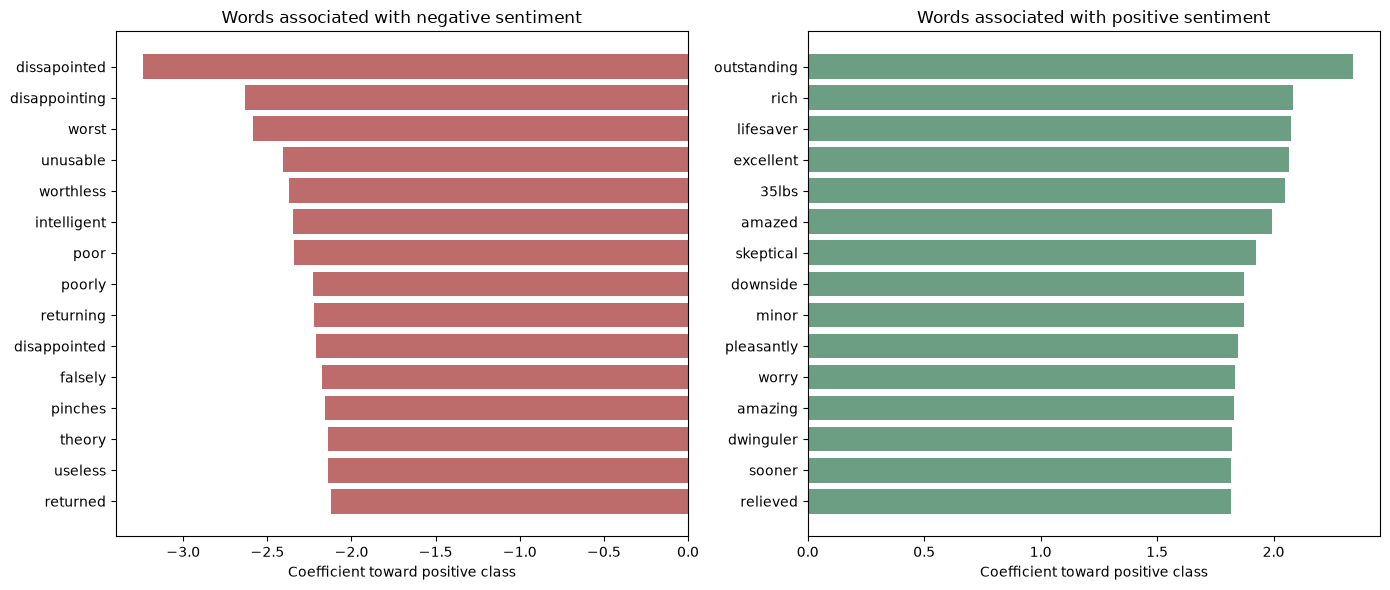

In [29]:
feature_names = vectorizer.get_feature_names_out()

positive_class_index = list(model.classes_).index("positive")

coefficients = model.coef_[0]

if positive_class_index == 0:
    coefficients = -coefficients

coefficient_table = pd.DataFrame({
    "word": feature_names,
    "coefficient": coefficients,
})

top_positive = coefficient_table.nlargest(
    15, "coefficient"
).sort_values("coefficient")

top_negative = coefficient_table.nsmallest(
    15, "coefficient"
).sort_values("coefficient", ascending=False)

print("Words associated with positive sentiment:")
display(
    coefficient_table
    .nlargest(10, "coefficient")
    .reset_index(drop=True)
)

print("Words associated with negative sentiment:")
display(
    coefficient_table
    .nsmallest(10, "coefficient")
    .sort_values("coefficient")
    .reset_index(drop=True)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].barh(
    top_negative["word"],
    top_negative["coefficient"],
    color="#bd6b6b",
)
axes[0].set_title("Words associated with negative sentiment")
axes[0].set_xlabel("Coefficient toward positive class")

axes[1].barh(
    top_positive["word"],
    top_positive["coefficient"],
    color="#6b9e83",
)
axes[1].set_title("Words associated with positive sentiment")
axes[1].set_xlabel("Coefficient toward positive class")

plt.tight_layout()
plt.show()

## 5. Evaluating the full-vocabulary model

We evaluate the classifier on the held-out test set.

We report accuracy, precision, recall, and F1-score. We also inspect a confusion matrix to understand which classes are misclassified.

In addition to numerical metrics, we inspect a few reviews with the highest and lowest predicted probabilities of positive sentiment.

In [30]:
y_pred = model.predict(X_test_vectorized)

In [31]:
y_proba = model.predict_proba(X_test_vectorized)

positive_class_index = list(model.classes_).index("positive")
positive_probs = y_proba[:, positive_class_index]

print(
    "Example predicted probabilities for positive sentiment:",
    positive_probs[:5],
)

Example predicted probabilities for positive sentiment: [0.99641287 0.99917126 0.99953202 0.96838947 0.87427804]


In [32]:
review_results = pd.DataFrame({
    "review": X_test.reset_index(drop=True),
    "actual_sentiment": y_test.reset_index(drop=True),
    "predicted_sentiment": y_pred,
    "positive_probability": positive_probs,
})

print("Five reviews with the highest predicted positive probability:")

display(
    review_results
    .nlargest(5, "positive_probability")
    .reset_index(drop=True)
)

print("Five reviews with the lowest predicted positive probability:")

display(
    review_results
    .nsmallest(5, "positive_probability")
    .reset_index(drop=True)
)

Five reviews with the highest predicted positive probability:


,review,actual_sentiment,predicted_sentiment,positive_probability
0,"We are big Best Bottoms fans here, but I wante...",positive,positive,1.0
1,AMAZING stroller! It took me about 2 minutes ...,positive,positive,1.0
2,"Choice - Quinny Buzz 2011 in ""Brown Boost""To s...",positive,positive,1.0
3,I bought this right before the KeyFit 30 came ...,positive,positive,1.0
4,We LOVE this seat! As parents to 8 children ra...,positive,positive,1.0


Five reviews with the lowest predicted positive probability:


,review,actual_sentiment,predicted_sentiment,positive_probability
0,I had to return this stroller for three reason...,negative,negative,1.080256e-18
1,I am so incredibly disappointed with the strol...,negative,negative,3.884569e-15
2,I purchased this in the black color. For some...,negative,negative,3.112574e-14
3,This is the first review I have ever written o...,negative,negative,5.737433e-13
4,PLEASE HEED THE OTHER REVIEWERS WARNINGS ON TH...,negative,negative,5.783987e-13


Classification report:
              precision    recall  f1-score   support

    negative       0.82      0.73      0.78      5279
    positive       0.95      0.97      0.96     27916

    accuracy                           0.93     33195
   macro avg       0.89      0.85      0.87     33195
weighted avg       0.93      0.93      0.93     33195


Summary metrics:


,accuracy,precision_positive,recall_positive,f1_positive,precision_negative,recall_negative,f1_negative,f1_macro
model,,,,,,,,
Logistic Regression - full vocabulary,0.9326,0.9508,0.97,0.9603,0.8225,0.7348,0.7762,0.8683


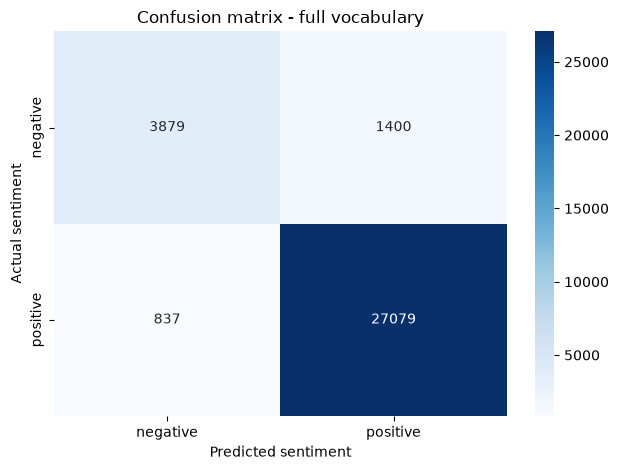

In [33]:
full_result = evaluate_predictions(
    "Logistic Regression - full vocabulary",
    y_test,
    y_pred,
)

print("Classification report:")
print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0,
    )
)

print("\nSummary metrics:")
display(
    pd.DataFrame([full_result])
    .set_index("model")
    .round(4)
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["negative", "positive"],
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["negative", "positive"],
    yticklabels=["negative", "positive"],
)

plt.title("Confusion matrix - full vocabulary")
plt.xlabel("Predicted sentiment")
plt.ylabel("Actual sentiment")
plt.tight_layout()
plt.show()

## 6. Model B - predefined vocabulary of 20 words

We now restrict the vocabulary to a predefined list of 20 words.

This experiment shows how a compact feature representation affects model performance and training time.

The vocabulary is specified in advance rather than selected automatically from the dataset. Therefore, it should be interpreted as a controlled comparison, not as a general feature-selection method.

In [34]:
significant_words = [
    "love",
    "great",
    "easy",
    "old",
    "little",
    "perfect",
    "loves",
    "well",
    "able",
    "car",
    "broke",
    "less",
    "even",
    "waste",
    "disappointed",
    "work",
    "product",
    "money",
    "would",
    "return",
]

In [35]:
vectorizer_sig = CountVectorizer(
    vocabulary=significant_words
)

X_train_vectorized_sig = vectorizer_sig.fit_transform(X_train)
X_test_vectorized_sig = vectorizer_sig.transform(X_test)

model_sig = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE,
)

start = perf_counter()

model_sig.fit(
    X_train_vectorized_sig,
    y_train,
)

limited_train_seconds = perf_counter() - start

y_pred_sig = model_sig.predict(X_test_vectorized_sig)

print(
    "Vocabulary size:",
    len(vectorizer_sig.get_feature_names_out()),
)

print(
    f"Training time: {limited_train_seconds:.4f} seconds"
)

print("\nClassification report:")
print(
    classification_report(
        y_test,
        y_pred_sig,
        zero_division=0,
    )
)

limited_result = evaluate_predictions(
    "Logistic Regression - 20 words",
    y_test,
    y_pred_sig,
)

display(
    pd.DataFrame([limited_result])
    .set_index("model")
    .round(4)
)

Vocabulary size: 20
Training time: 0.2304 seconds

Classification report:
              precision    recall  f1-score   support

    negative       0.76      0.27      0.39      5279
    positive       0.88      0.98      0.93     27916

    accuracy                           0.87     33195
   macro avg       0.82      0.62      0.66     33195
weighted avg       0.86      0.87      0.84     33195



,accuracy,precision_positive,recall_positive,f1_positive,precision_negative,recall_negative,f1_negative,f1_macro
model,,,,,,,,
Logistic Regression - 20 words,0.8695,0.8762,0.9838,0.9269,0.7554,0.265,0.3924,0.6596


,word,coefficient
0,disappointed,-2.3821
1,return,-2.0863
2,waste,-1.9850
3,broke,-1.6594
4,money,-0.8983
5,work,-0.6219
6,even,-0.5176
7,would,-0.3474
8,product,-0.3124
9,less,-0.1721


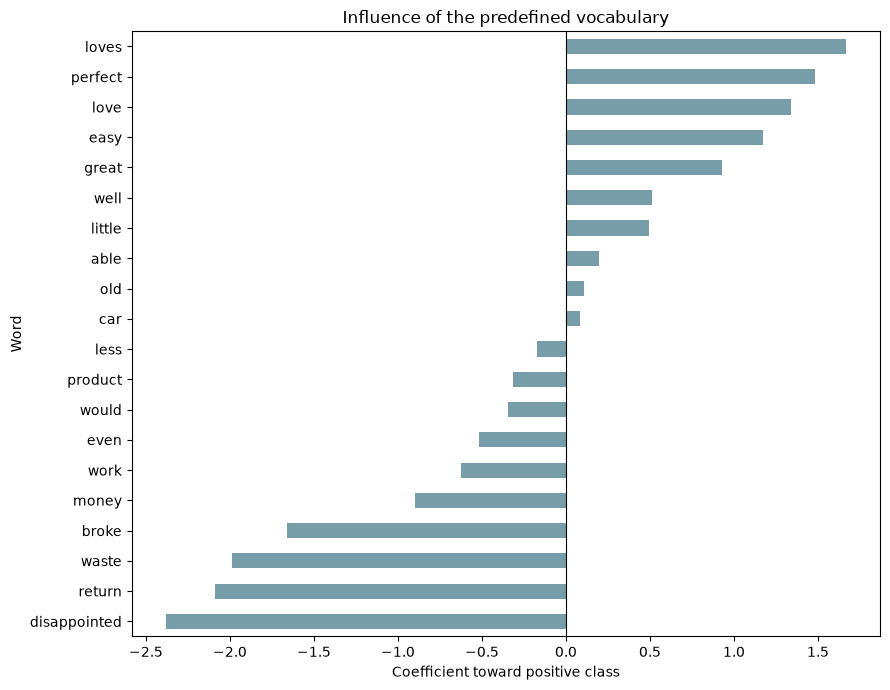

In [36]:
limited_coefficients = model_sig.coef_[0]

positive_class_index = list(model_sig.classes_).index("positive")

if positive_class_index == 0:
    limited_coefficients = -limited_coefficients

limited_coefficient_table = pd.DataFrame({
    "word": vectorizer_sig.get_feature_names_out(),
    "coefficient": limited_coefficients,
}).sort_values("coefficient")

display(
    limited_coefficient_table
    .reset_index(drop=True)
    .round(4)
)

ax = limited_coefficient_table.plot(
    x="word",
    y="coefficient",
    kind="barh",
    figsize=(9, 7),
    legend=False,
    color="#779da8",
)

ax.axvline(0, color="black", linewidth=0.8)
ax.set_title("Influence of the predefined vocabulary")
ax.set_xlabel("Coefficient toward positive class")
ax.set_ylabel("Word")

plt.tight_layout()
plt.show()

Model comparison:


,accuracy,precision_positive,recall_positive,f1_positive,precision_negative,recall_negative,f1_negative,f1_macro,training_time_seconds
model,,,,,,,,,
Majority-class baseline,0.8410,0.8410,1.0000,0.9136,0.0000,0.0000,0.0000,0.4568,0.0000
Logistic Regression - full vocabulary,0.9326,0.9508,0.9700,0.9603,0.8225,0.7348,0.7762,0.8683,16.2839
Logistic Regression - 20 words,0.8695,0.8762,0.9838,0.9269,0.7554,0.2650,0.3924,0.6596,0.2304


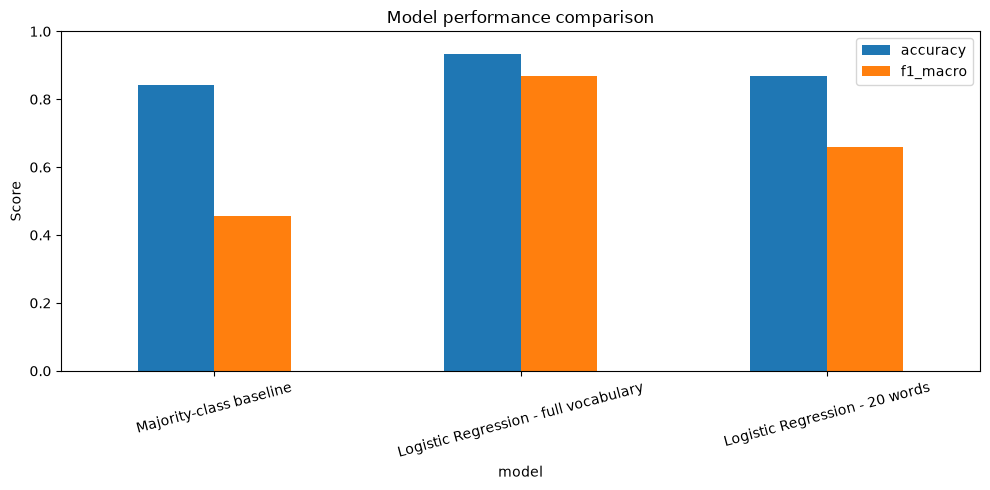

Approximate training times:


,training_time_seconds
model,
Majority-class baseline,0.0000
Logistic Regression - full vocabulary,16.2839
Logistic Regression - 20 words,0.2304


In [37]:
results_df = pd.DataFrame([
    baseline_result,
    full_result,
    limited_result,
]).set_index("model")

results_df["training_time_seconds"] = [
    0.0,
    full_train_seconds,
    limited_train_seconds,
]

print("Model comparison:")
display(results_df.round(4))

ax = results_df[
    ["accuracy", "f1_macro"]
].plot(
    kind="bar",
    figsize=(10, 5),
)

ax.set_title("Model performance comparison")
ax.set_ylabel("Score")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()

print("Approximate training times:")
display(
    results_df[["training_time_seconds"]]
    .round(4)
)

## 7. Conclusions and limitations

### Key findings

The Logistic Regression model using the full vocabulary achieved an accuracy of **93.26%**, outperforming the majority-class baseline (84.10%). Its F1-score for positive reviews was 0.9603, while the recall for negative reviews was 0.73.

Restricting the vocabulary to 20 predefined words reduced training time from approximately 16.28 seconds to 0.23 seconds. However, accuracy decreased from 93.26% to 86.95%, macro F1-score decreased from 0.8683 to 0.6596, and recall for negative reviews fell from 0.7348 to 0.2650. Although the restricted model identified most positive reviews, it failed to detect a large proportion of negative reviews.

These results illustrate a trade-off between computational efficiency and predictive performance. The full-vocabulary model performed better overall, particularly when identifying negative sentiment, while the compact model required substantially less training time.

### Limitations

- **Class imbalance:** Positive reviews account for approximately 84% of the retained dataset. Accuracy alone is therefore insufficient for evaluating model quality.
- **Rating-derived labels:** Sentiment is inferred from star ratings, which may be subjective or inconsistent.
- **Limited text representation:** The bag-of-words approach does not capture word order, context, sarcasm, or negation reliably.
- **Predefined vocabulary:** The list of 20 words was specified in advance and may not generalize to other review datasets.
- **Dataset-specific results:** Performance on this dataset does not guarantee similar results on other products or customer populations.

### Conclusion

The experiment shows that a full bag-of-words vocabulary provides a stronger classification baseline than the predefined 20-word vocabulary for this dataset. The restricted model is faster, but its low recall for negative reviews is an important limitation. Future work could investigate TF-IDF features, n-grams, class weighting, and additional evaluation metrics to improve the detection of negative sentiment.